### Abraham Rodriguez Vazqzuez
#### ITESO - Deep Learning Spring 2024
#### Proyecto Final - IMU-GPS Sensor fusion based in Deep Learning 

In [ ]:
import pandas as pd
import torch

names=["imu_accx","imu_accy","imu_accz","imu_wx","imu_wy","imu_wz","imu_magx","imu_magy","imu_magz",
       "gps_velx","gps_vely","gps_velz",
       "prev_state_posx","prev_state_posy","prev_state_posz",
       "prev_state_quatw","prev_state_quatx","prev_state_quaty","prev_state_quatz",
       "gt_state_posx","gt_state_posy","gt_state_posz",
       "gt_state_quatw","gt_state_quatx","gt_state_quaty","gt_state_quatz",]

df = pd.read_csv("dataset.csv",names=names)

NOTES: poner comentario de los inputs necesarios para el filtro de kalman, estos vectores tienen este proposito
% meter diagramas, documentar ejercicios para acordarme

% Documentacion del proyecto,
codigos son apendices,
esta figura es buena, 
en algun momento, 
adaptar antes y despues para tener texto fluido
si mucha parte importante.


In [19]:
df

,imu_accx,imu_accy,imu_accz,imu_wx,imu_wy,imu_wz,imu_magx,imu_magy,imu_magz,gps_velx,...,prev_state_quatz_lag_1,prev_state_quatz_lag_2,prev_state_quatz_lag_3,prev_state_quatz_lag_4,prev_state_quatz_lag_5,prev_state_quatz_lag_6,prev_state_quatz_lag_7,prev_state_quatz_lag_8,prev_state_quatz_lag_9,prev_state_quatz_lag_10
10,3.388205,-3.457596,8.496833,0.050178,0.056723,0.064359,89.6,88.6,149.4,0.562840,...,0.850038,0.850025,0.850011,0.849998,0.849986,0.849972,0.849959,0.849946,0.849933,0.849919
11,-1.715638,5.213911,10.133508,0.051269,0.058905,0.064359,89.6,88.6,149.4,0.562840,...,0.850051,0.850038,0.850025,0.850011,0.849998,0.849986,0.849972,0.849959,0.849946,0.849933
12,0.598200,0.894907,7.977595,0.057814,0.054542,0.059996,89.6,88.6,149.4,0.562840,...,0.850064,0.850051,0.850038,0.850025,0.850011,0.849998,0.849986,0.849972,0.849959,0.849946
13,0.892514,0.978655,9.939691,0.058905,0.052360,0.062177,89.6,88.6,149.4,0.562840,...,0.850077,0.850064,0.850051,0.850038,0.850025,0.850011,0.849998,0.849986,0.849972,0.849959
14,0.911657,0.842266,10.186150,0.056723,0.052360,0.064359,89.6,88.6,149.4,0.562840,...,0.850090,0.850077,0.850064,0.850051,0.850038,0.850025,0.850011,0.849998,0.849986,0.849972
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22555,-0.100498,0.358920,10.760422,0.056723,0.056723,0.049087,90.1,86.9,149.8,-0.254792,...,0.827982,0.827992,0.828002,0.828013,0.828022,0.828030,0.828038,0.828045,0.828053,0.828060
22556,1.217935,1.397395,9.690840,0.054542,0.057814,0.046906,90.1,86.9,149.8,-0.254792,...,0.827971,0.827982,0.827992,0.828002,0.828013,0.828022,0.828030,0.828038,0.828045,0.828053
22557,-0.133997,0.344563,10.781957,0.055632,0.051269,0.051269,90.1,86.9,149.8,-0.254792,...,0.827959,0.827971,0.827982,0.827992,0.828002,0.828013,0.828022,0.828030,0.828038,0.828045
22558,1.227506,1.380646,9.580771,0.055632,0.061087,0.043633,90.1,86.9,149.8,-0.254792,...,0.827947,0.827959,0.827971,0.827982,0.827992,0.828002,0.828013,0.828022,0.828030,0.828038


In [2]:
# Select columns for lag
features_forlag = ["imu_accx", "imu_accy", "imu_accz", "imu_wx", "imu_wy", "imu_wz",
            "imu_magx", "imu_magy", "imu_magz", "gps_velx", "gps_vely", "gps_velz",
            "prev_state_posx", "prev_state_posy", "prev_state_posz",
            "prev_state_quatw", "prev_state_quatx", "prev_state_quaty", "prev_state_quatz"]

# Define the number of lags
n_lags = 10

# Add lagged features for each specified column
for feature in features_forlag:
    for lag in range(1, n_lags + 1):
        df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)

# Drop rows with NaN values that result from creating lags
df.dropna(inplace=True)

# Create a new DataFrame where each column has arrays that combine current and lagged values of each feature
df_transformed = pd.DataFrame({feature: df[ [f'{feature}_lag_{i}' for i in range(n_lags, 0,-1)] + [feature]].apply(lambda row: row.values, axis=1) for feature in features_forlag})

df_transformed = pd.concat((df_transformed, df[["gt_state_posx","gt_state_posy","gt_state_posz","gt_state_quatw","gt_state_quatx","gt_state_quaty","gt_state_quatz"]]),axis=1)


C:\Users\noxuz\AppData\Local\Temp\ipykernel_44052\1780005521.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)
C:\Users\noxuz\AppData\Local\Temp\ipykernel_44052\1780005521.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)
C:\Users\noxuz\AppData\Local\Temp\ipykernel_44052\1780005521.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor p

In [3]:
df_transformed

,imu_accx,imu_accy,imu_accz,imu_wx,imu_wy,imu_wz,imu_magx,imu_magy,imu_magz,gps_velx,...,prev_state_quatx,prev_state_quaty,prev_state_quatz,gt_state_posx,gt_state_posy,gt_state_posz,gt_state_quatw,gt_state_quatx,gt_state_quaty,gt_state_quatz
10,"[3.6442344, 0.9954048, 0.9068712, 0.9260136, 3...","[-3.5198088, 0.8757648, 0.9475488, 0.7968024, ...","[10.3177536, 10.9494528, 9.9372984, 9.8272296,...","[0.0523598775598299, 0.0654498469497874, 0.049...","[0.0665406777322838, 0.0589048622548086, 0.057...","[0.0643590161672909, 0.0567232006898157, 0.064...","[89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89....","[88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88....","[149.4, 149.4, 149.4, 149.4, 149.4, 149.4, 149...","[0.562840216262399, 0.562840216262399, 0.56284...",...,"[0.0513264027449581, 0.0513261499254631, 0.051...","[0.0147326464302828, 0.0147333843894244, 0.014...","[0.849919492386084, 0.849932949840514, 0.84994...",2.720947,5.706484,0.715963,0.523966,0.051323,0.014743,0.850064
11,"[0.9954048, 0.9068712, 0.9260136, 3.6179136, -...","[0.8757648, 0.9475488, 0.7968024, -3.5748432, ...","[10.9494528, 9.9372984, 9.8272296, 9.8248368, ...","[0.0654498469497874, 0.0490873852123405, 0.049...","[0.0589048622548086, 0.0578140314723122, 0.053...","[0.0567232006898157, 0.0643590161672909, 0.061...","[89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89....","[88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88....","[149.4, 149.4, 149.4, 149.4, 149.4, 149.4, 149...","[0.562840216262399, 0.562840216262399, 0.56284...",...,"[0.0513261499254631, 0.0513259184195276, 0.051...","[0.0147333843894244, 0.014734158391743, 0.0147...","[0.849932949840514, 0.849946231729166, 0.84995...",2.723606,5.710779,0.715328,0.523945,0.051323,0.014745,0.850077
12,"[0.9068712, 0.9260136, 3.6179136, -1.662996, 3...","[0.9475488, 0.7968024, -3.5748432, 5.132556, -...","[9.9372984, 9.8272296, 9.8248368, 10.1024016, ...","[0.0490873852123405, 0.0490873852123405, 0.050...","[0.0578140314723122, 0.0534507083423263, 0.055...","[0.0643590161672909, 0.0610865238198015, 0.061...","[89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89....","[88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88....","[149.4, 149.4, 149.4, 149.4, 149.4, 149.4, 149...","[0.562840216262399, 0.562840216262399, 0.56284...",...,"[0.0513259184195276, 0.0513256715528864, 0.051...","[0.014734158391743, 0.0147349966883749, 0.0147...","[0.849946231729166, 0.849959452531599, 0.84997...",2.726160,5.714909,0.714757,0.523923,0.051323,0.014746,0.850090
13,"[0.9260136, 3.6179136, -1.662996, 3.3882048, -...","[0.7968024, -3.5748432, 5.132556, -3.1441392, ...","[9.8272296, 9.8248368, 10.1024016, 10.073688, ...","[0.0490873852123405, 0.050178215994837, 0.0589...","[0.0534507083423263, 0.0556323699073193, 0.054...","[0.0610865238198015, 0.0610865238198015, 0.066...","[89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89....","[88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88....","[149.4, 149.4, 149.4, 149.4, 149.4, 149.4, 149...","[0.562840216262399, 0.562840216262399, 0.56284...",...,"[0.0513256715528864, 0.0513254042037798, 0.051...","[0.0147349966883749, 0.0147358813964924, 0.014...","[0.849959452531599, 0.849972356116832, 0.84998...",2.728816,5.719205,0.714172,0.523902,0.051322,0.014747,0.850103
14,"[3.6179136, -1.662996, 3.3882048, -1.7132448, ...","[-3.5748432, 5.132556, -3.1441392, 5.2952664, ...","[9.8248368, 10.1024016, 10.073688, 10.7484576,...","[0.050178215994837, 0.0589048622548086, 0.0545...","[0.0556323699073193, 0.0545415391248228, 0.058...","[0.0610865238198015, 0.0665406777322838, 0.067...","[89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89.6, 89....","[88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88.6, 88....","[149.4, 149.4, 149.4, 149.4, 149.4, 149.4, 149...","[0.562840216262399, 0.562840216262399, 0.56284...",...,"[0.0513254042037798, 0.0513250764875828, 0.051...","[0.0147358813964924, 0.0147368303748686, 0.014...","[0.849972356116832, 0.849985566543913, 0.84999...",2.731472,5.723507,0.713665,0.523882,0.051322,0.014749,0.850116
...,...,...,...,...,...,...,

In [4]:
def quaternion_angular_distance_degrees(q1, q2):
    q2_conjugate = q2.clone()
    q2_conjugate[:, 1:] = -q2_conjugate[:, 1:]
    product = torch.stack((q1[:, 0] * q2_conjugate[:, 0] - q1[:, 1] * q2_conjugate[:, 1] - q1[:, 2] * q2_conjugate[:, 2] - q1[:, 3] * q2_conjugate[:, 3],
                           q1[:, 0] * q2_conjugate[:, 1] + q1[:, 1] * q2_conjugate[:, 0] + q1[:, 2] * q2_conjugate[:, 3] - q1[:, 3] * q2_conjugate[:, 2],
                           q1[:, 0] * q2_conjugate[:, 2] - q1[:, 1] * q2_conjugate[:, 3] + q1[:, 2] * q2_conjugate[:, 0] + q1[:, 3] * q2_conjugate[:, 1],
                           q1[:, 0] * q2_conjugate[:, 3] + q1[:, 1] * q2_conjugate[:, 2] - q1[:, 2] * q2_conjugate[:, 1] + q1[:, 3] * q2_conjugate[:, 0]), dim=1)
    abs_part = torch.clamp(torch.abs(product[:, 0]), -1.0, 1.0)
    theta_radians = 2 * torch.acos(abs_part)
    theta_degrees = theta_radians * (180 / torch.pi)
    return theta_degrees

In [5]:
from sklearn.model_selection import train_test_split

dataset = df_transformed.to_numpy()
X = dataset[:,:19]
Y = dataset[:,19:]

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.15, shuffle=True)

In [7]:
from torch.utils.data import Dataset,DataLoader
import numpy as np

class fusionDataset(Dataset):
    def __init__(self,x,y):
        self.x = x
        self.y = y

    def __len__(self):
        return len(self.x)
    
    def __getitem__(self,idx):
        x,y = np.array(self.x[idx].tolist()), np.array(self.y[idx].tolist())

        x = torch.tensor(x,dtype=torch.float)
        y = torch.tensor(y,dtype=torch.float)
        return x,y


In [8]:
train_dataset = fusionDataset(X_train,Y_train)
test_dataset = fusionDataset(X_test,Y_test)

train_loader = DataLoader(train_dataset,batch_size=1000)
test_loader = DataLoader(test_dataset,batch_size=1000)

In [9]:
import torch.nn as nn

class fuseModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1d = nn.Conv1d(in_channels=19,out_channels=19,kernel_size=3)
        self.lstm = nn.LSTM(input_size=19,hidden_size=256,num_layers=1,batch_first=True)
        self.flat = nn.Flatten()
        self.linear1 = nn.Linear(in_features=2304,out_features=512)
        self.relu1 = nn.ReLU()
        self.linear2 = nn.Linear(in_features=512,out_features=128)
        self.relu2 = nn.ReLU()
        self.linear3 = nn.Linear(in_features=128,out_features=7)

    def forward(self,x):
        outconv = self.conv1d(x) # Expects N,C,L
        output, (h_n, c_n) = self.lstm(outconv.permute((0,2,1))) # Expects N,L,H
        flat = self.flat(output)
        out1 = self.relu1(self.linear1(flat))
        out2 = self.relu2(self.linear2(out1))
        out3 = self.linear3(out2)
        
        return out3

In [10]:
def calculate_mse(model,test_loader):
    model.eval()
    mse = 0
    n = 0
    criterion = nn.MSELoss()
    
    with torch.no_grad():
        for seq,label in test_loader:
            seq,label = seq.to("cuda"),label.to("cuda")
            y_pred = model(seq)
            # Quaterion error is computed different
            pos_label,quat_label = label[:,0:3],label[:,3:8]
            pos_pred,quat_pred = y_pred[:,0:3],y_pred[:,3:8]

            loss_pos = criterion(pos_pred,pos_label)
            loss_quat = criterion(quat_pred,quat_label)
            loss = loss_pos+loss_quat

            mse += loss.item()
            n+=1

    model.train()
    return round(mse/n,6)

In [11]:
from torch.optim import SGD

device = "cuda"
model = fuseModel()

model.to(device)
model.train()

epochs = 130

optimizer = SGD(model.parameters(),lr=1e-3)
criterion = nn.MSELoss()

losses = []
for e in range(epochs):
    loss_e = 0
    for seq,label in train_loader:
        seq,label = seq.to(device),label.to(device)

        y_pred = model(seq)

        # Quaterion error is computed different
        pos_label,quat_label = label[:,0:3],label[:,3:8]
        pos_pred,quat_pred = y_pred[:,0:3],y_pred[:,3:8]
    
        loss_pos = criterion(pos_pred,pos_label)
        #loss_quat = torch.mean(torch.square(quaternion_angular_distance_degrees(quat_pred,quat_label)))
        loss_quat = criterion(quat_pred,quat_label)

        loss = loss_pos+loss_quat
        loss_e+=loss.item()
        losses.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    mse = calculate_mse(model,test_loader)

    print(f"epoch: {e}, loss_e: {loss_e}, MSE_test:{mse}")

epoch: 0, loss_e: 619.8014965057373, MSE_test:29.589244
epoch: 1, loss_e: 533.076566696167, MSE_test:23.447787
epoch: 2, loss_e: 444.16601181030273, MSE_test:21.826977
epoch: 3, loss_e: 429.2401924133301, MSE_test:21.33657
epoch: 4, loss_e: 417.5044059753418, MSE_test:20.809201
epoch: 5, loss_e: 403.45826530456543, MSE_test:22.121359
epoch: 6, loss_e: 403.61070823669434, MSE_test:18.817318
epoch: 7, loss_e: 397.1830406188965, MSE_test:18.428151
epoch: 8, loss_e: 400.3069705963135, MSE_test:17.868593
epoch: 9, loss_e: 393.27471923828125, MSE_test:16.176301
epoch: 10, loss_e: 406.153338432312, MSE_test:20.147241
epoch: 11, loss_e: 383.1112232208252, MSE_test:15.69558
epoch: 12, loss_e: 370.466814994812, MSE_test:17.416822
epoch: 13, loss_e: 350.8219976425171, MSE_test:27.75834
epoch: 14, loss_e: 398.2691421508789, MSE_test:14.311998
epoch: 15, loss_e: 365.7058515548706, MSE_test:18.302185
epoch: 16, loss_e: 341.00194454193115, MSE_test:12.355599
epoch: 17, loss_e: 267.26865005493164, MSE

In [12]:
torch.save(model,"final_project_sensorFusion_model.pth")

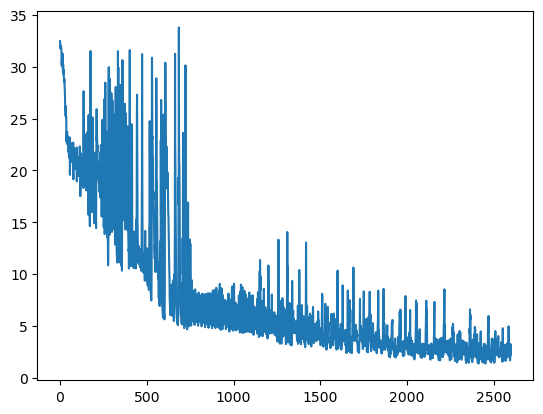

In [13]:
import matplotlib.pyplot as plt

plt.plot(range(len(losses)),losses)
plt.show()

In [14]:
def calculate_mse_val(model,val_loader):
    model.eval()
    model.to("cpu")
    mse_pos = 0
    mse_quat = 0
    n = 0
    criterion = nn.MSELoss()
    
    path_predicho = []
    path_real = []

    with torch.no_grad():
        for seq,label in val_loader:
            seq,label = seq.to("cpu"),label.to("cpu")
            y_pred = model(seq)
            # Quaterion error is computed different
            pos_label,quat_label = label[:,0:3],label[:,3:8]
            pos_pred,quat_pred = y_pred[:,0:3],y_pred[:,3:8]

            loss_pos = criterion(pos_pred,pos_label)
            loss_quat = criterion(quat_pred,quat_label)

            mse_pos += loss_pos.item()
            mse_quat += loss_quat.item()
            n+=1

            # Append to output
            path_predicho.extend(pos_pred)
            path_real.extend(pos_label) 

    model.train()
    return round(mse_pos/n,6), round(mse_quat/n,6), path_predicho, path_real

In [15]:
# max 140 seconds
startsecond = 65
endseconds = 75

sample_start = startsecond * 160
sample_end = endseconds * 160

# Get intermediate vals
X_val = dataset[sample_start:sample_end,:19]
Y_val = dataset[sample_start:sample_end,19:]

val_dataset = fusionDataset(X_val,Y_val)
val_loader = DataLoader(val_dataset,batch_size=10)

mse_pos, mse_quat, path_predicho, path_real = calculate_mse_val(model,val_loader)
print(f"mse_pos: {mse_pos}, mse_quat: {mse_quat}")

mse_pos: 1.109459, mse_quat: 0.001735


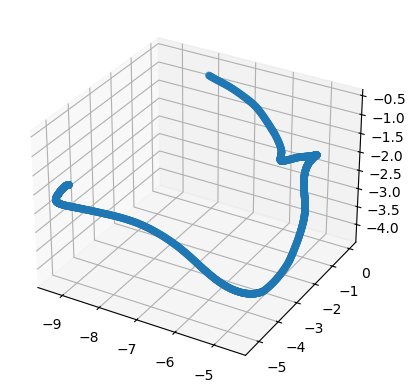

In [16]:
import matplotlib.pyplot as plt

plotarr = [r.numpy() for r in path_real]

x = []
y = []
z = []

for r in plotarr:
    x.append(r[0])
    y.append(r[1])
    z.append(r[2])

fig = plt.figure()
ax = plt.axes(projection='3d')

# Plotting
ax.scatter(x, y, z)

plt.show()

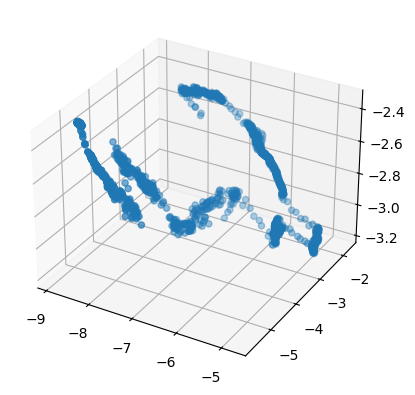

In [17]:
plotarr2 = [r.numpy() for r in path_predicho]

x2 = []
y2 = []
z2 = []

for r2 in plotarr2:
    x2.append(r2[0])
    y2.append(r2[1])
    z2.append(r2[2])

fig = plt.figure()
ax = plt.axes(projection='3d')

# Plotting
ax.scatter(x2, y2, z2)

plt.show()

In [18]:
path_predicho

[tensor([-8.8077, -4.8410, -2.3702]),
 tensor([-8.8175, -4.8310, -2.3739]),
 tensor([-8.8117, -4.8402, -2.3718]),
 tensor([-8.8180, -4.8331, -2.3715]),
 tensor([-8.8089, -4.8424, -2.3712]),
 tensor([-8.8184, -4.8369, -2.3717]),
 tensor([-8.8122, -4.8449, -2.3726]),
 tensor([-8.8212, -4.8395, -2.3689]),
 tensor([-8.8023, -4.8545, -2.3713]),
 tensor([-8.8249, -4.8420, -2.3707]),
 tensor([-8.8084, -4.8553, -2.3693]),
 tensor([-8.8128, -4.8496, -2.3688]),
 tensor([-8.8098, -4.8552, -2.3698]),
 tensor([-8.8162, -4.8486, -2.3659]),
 tensor([-8.7993, -4.8624, -2.3693]),
 tensor([-8.8164, -4.8511, -2.3649]),
 tensor([-8.8009, -4.8653, -2.3691]),
 tensor([-8.8175, -4.8551, -2.3643]),
 tensor([-8.8045, -4.8685, -2.3664]),
 tensor([-8.8194, -4.8549, -2.3631]),
 tensor([-8.8137, -4.8640, -2.3669]),
 tensor([-8.8233, -4.8529, -2.3620]),
 tensor([-8.8133, -4.8604, -2.3640]),
 tensor([-8.8248, -4.8521, -2.3614]),
 tensor([-8.8154, -4.8600, -2.3639]),
 tensor([-8.8280, -4.8530, -2.3619]),
 tensor([-8.